# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [3]:
# Import standard libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
# (Make sure your file is uploaded to the left sidebar or use your Assignment 6 output filename)
df = pd.read_csv('/content/listings.csv.gz')

# Quick check to ensure it loaded correctly
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,741434727341232814,https://www.airbnb.com/rooms/741434727341232814,20260917204843,2026-09-19,previous scrape,Private bedroom in fantastic shared home,Keep it simple at this peaceful and centrally-...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,123504982,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
1,1775522910816348491,https://www.airbnb.com/rooms/1775522910816348491,20260917204843,2026-09-20,NaN,Apartment in Austin,Entire place apartment,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,714096542,...,5.00,5.00,5.00,NaN,NaN,1,1,0,0,1.00
2,795719559342015447,https://www.airbnb.com/rooms/795719559342015447,20260917204843,2026-09-19,NaN,Sunshine Cove Guesthouse,This 1-bedroom guesthouse in Dripping Springs ...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,27228465,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
3,755672804161441366,https://www.airbnb.com/rooms/755672804161441366,20260917204843,2026-09-20,NaN,"Hotel Ella, Premiere Pool View",For those seeking tranquil views and additiona...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,78455367,...,NaN,NaN,NaN,NaN,NaN,11,0,11,0,NaN
4,613088323255036264,https://www.airbnb.com/rooms/613088323255036264,20260917204843,2026-09-20,NaN,#1- Guest Room with Two double Beds,Keeping Austin local. <br />Deep in the heart ...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,386381014,...,4.79,4.75,4.61,NaN,NaN,3,1,2,0,3.06


## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

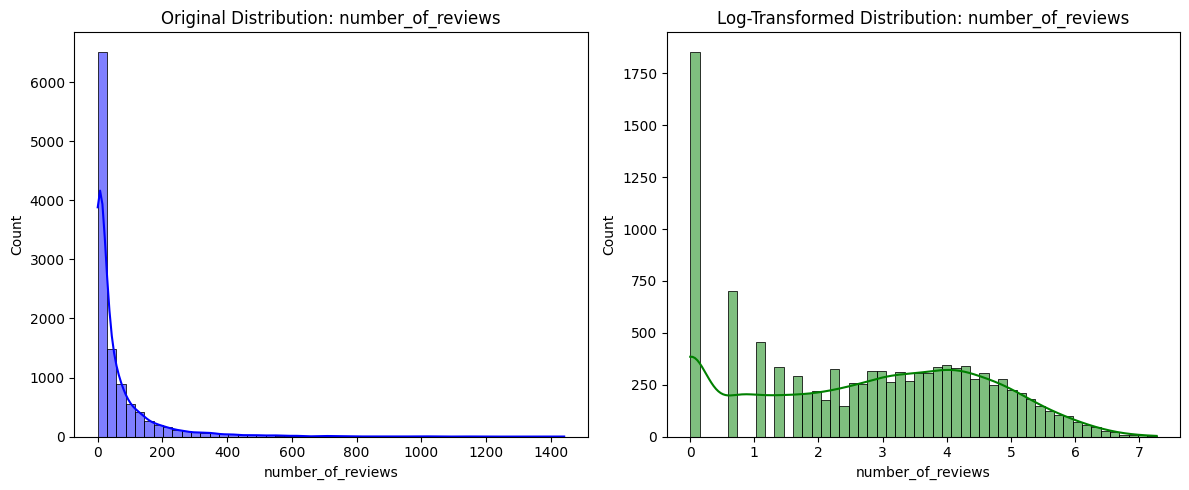

In [4]:
# Choose a numeric column to check for skew, e.g., 'price'
# (Note: if 'price' is read as a string with dollar signs, make sure to clean it or pick another numeric column like 'number_of_reviews')
target_column = 'number_of_reviews'

# 1. Plot the original histogram
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df[target_column].dropna(), bins=50, kde=True, color='blue')
plt.title(f'Original Distribution: {target_column}')

# 2. Apply a log transformation (adding 1 to handle any zero values)
transformed_column = np.log1p(df[target_column])

# 3. Plot the transformed histogram
plt.subplot(1, 2, 2)
sns.histplot(transformed_column.dropna(), bins=50, kde=True, color='green')
plt.title(f'Log-Transformed Distribution: {target_column}')

plt.tight_layout()
plt.show()

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. number_of_reviews

2. I applied a log transformation (np.log1p), because real-world Airbnb review data is heavily right-skewed with a long tail of extreme outliers, which can heavily bias models or skew stakeholder analysis.

3. It compressed the wide range of values into a more balanced, bell-shaped distribution. This makes it much easier to visualize patterns, summarize averages fairly, and prepare features for machine learning models.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [6]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 1. Choose two numeric columns with different ranges (e.g., 'minimum_nights' and 'number_of_reviews')
col1 = 'minimum_nights'
col2 = 'number_of_reviews'

# 2. Initialize the scalers
min_max_scaler = MinMaxScaler()
z_scaler = StandardScaler()

# 3. Apply Min-Max scaling to the first column and Z-score normalization to the second
# We use fillna(0) to safely handle any missing values before scaling
df['minimum_nights_minmax'] = min_max_scaler.fit_transform(df[[col1]].fillna(0))
df['number_of_reviews_zscore'] = z_scaler.fit_transform(df[[col2]].fillna(0))

# 4. Verify the new columns were added and inspect their ranges
df[[col1, 'minimum_nights_minmax', col2, 'number_of_reviews_zscore']].head()

,minimum_nights,minimum_nights_minmax,number_of_reviews,number_of_reviews_zscore
0,90.0,0.246575,0,-0.539013
1,1.0,0.002740,1,-0.529848
2,2.0,0.005479,0,-0.539013
3,1.0,0.002740,0,-0.539013
4,1.0,0.002740,163,0.954882



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. I scaled minimum_nights (using min and max scaling which bounds the values between 0 and 1) and number_of_reviews (scaled using Z-score normalization, which centers the data around a mean of 0 with a standard deviation of 1).

2. They are critical when building maching learning models (like regression, clustering, or neural networks) that use distance and metrics or gradient descent, so that columns with naturally larger numeric ranges don't overpower or dominate columns with smaller ranges.

3. A data scientist or MLE on the pricing or reccomendation team would benefit the most from this.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [7]:
bin_edges = [-1, 0, 5, 20, df['number_of_reviews'].max()]
bin_labels = ['None', 'Low', 'Medium', 'High']
df['review_volume_category'] = pd.cut(
    df['number_of_reviews'].fillna(0),
    bins=bin_edges,
    labels=bin_labels
)
df['review_volume_category'].value_counts()

,count
review_volume_category,
High,5249
Medium,2015
Low,1992
None,1855


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. I grouped the number_of_reviews column into 4 categories (None, Low, Medium, and High).

2. Grouped categories make it much easier to quickly segment properties (e.g., distinguishing between brand-new listings with no track record versus established, high-volume listings) without getting bogged down in exact numerical counts.

3. A Marketing Manager or Host Success Team would find this useful to quickly identify which tiers need promotional help, onboard new hosts effectively, or run performance-tier campaigns.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [8]:
# 1. Create a revenue potential or pricing interaction feature (e.g., price per minimum stay)
# Ensure price is numeric by cleaning out dollar signs and commas if necessary
if df['price'].dtype == object:
    df['price_cleaned'] = df['price'].astype(str).str.replace('$', '').str.replace(',', '').astype(float)
else:
    df['price_cleaned'] = df['price']

# Feature 1: Total upfront minimum booking cost (price * minimum_nights)
df['upfront_booking_cost'] = df['price_cleaned'] * df['minimum_nights']

# Feature 2: Availability ratio (percentage of the year available, if availability_365 exists)
if 'availability_365' in df.columns:
    df['availability_ratio'] = df['availability_365'] / 365.0

# 2. Inspect the newly created features
df[['price_cleaned', 'minimum_nights', 'upfront_booking_cost', 'availability_ratio']].head()

,price_cleaned,minimum_nights,upfront_booking_cost,availability_ratio
0,79.74,90.0,7176.6,1.000000
1,158.00,1.0,158.0,0.923288
2,NaN,2.0,NaN,0.241096
3,428.80,1.0,428.8,0.810959
4,499.00,1.0,499.0,0.994521


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. I created upfront_booking_cost (by multiplying price and minimum_nights) to show the total minimum cash needed for a guest to book a stay, and availability_ratio (by dividing availability_365 by 365) to show the percentage of the year a property is available.

2. A guest or a platform pricing manager would use them to evaluate true affordability and listing utilization across the market.

3. They help guests instantly understand the true upfront commitment of a listing rather than just looking at a misleadingly low nightly price, while helping managers track annual availability trends.



## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [9]:
# 1. Choose a categorical column to encode, e.g., 'room_type'
categorical_col = 'room_type'

# 2. Apply one-hot encoding using pd.get_dummies()
df_encoded = pd.get_dummies(df, columns=[categorical_col], prefix=categorical_col, drop_first=True)

# 3. Verify the new encoded columns have been added to the DataFrame
print(f"Original columns count: {df.shape[1]}")
print(f"Encoded columns count: {df_encoded.shape[1]}")
df_encoded.filter(like=categorical_col).head()

Original columns count: 96
Encoded columns count: 98


,room_type_Hotel room,room_type_Private room,room_type_Shared room
0,False,True,False
1,False,False,False
2,False,False,False
3,False,True,False
4,False,False,False


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. I encoded the room_type column because machine learning algorithms and quantitative models cannot process text categories directly; they require numerical representations.
2. I used one-hot encoding via pandas (pd.get_dummies), which creates separate binary (0/1) columns for each category while dropping the first to avoid multicollinearity.
3. It allows data science models to accurately weigh structural differences between properties (such as entire homes versus private rooms) when predicting prices or powering recommendation systems.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [10]:
# Export the final transformed dataframe to a CSV file
df_encoded.to_csv('/content/cleaned_airbnb_data_7.csv', index=False)

print("Dataset successfully exported to /content/cleaned_airbnb_data_7.csv")

Dataset successfully exported to /content/cleaned_airbnb_data_7.csv


## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. The feature creation and one-hot encoding steps felt most impactful because they translate messy qualitative text and combined costs into tangible metrics that predictive models and business analysts can actually leverage.

2. Grouping review volumes into categories (None, Low, Medium, High) and creating availability metrics are extremely useful for local hosts evaluating their competitive tier and for city planners monitoring short-term rental activity.

3. I would feed these scaled, transformed, and encoded features into a supervised machine learning regression model to predict optimal nightly listing prices based on location, room type, and review volume.
4. It directly applies practical data wrangling and feature engineering principles to turn unstructured web-scraped marketplace data into an analysis-ready asset.



## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"